# SciAR: Step 2 data exploration with DuckDB
Query the existing ADS/SciX Parquet corpus through `NASA_ADS_UNIFIED`.
No astrophysics-only restriction is imposed. Start with the 2024 partition; expand the scope in the configuration cell.

The notebook reads the source files without changing them. Views stay lazy; only small summaries and examples are brought into pandas. Full-corpus distinct counts may take time and spill to local disk.


### Config

In [8]:
from pathlib import Path
import json
import duckdb
from IPython.display import display, Markdown

DATA_DIR = Path("/home/petrecc1/projects/SciAR/NASA_ADS_UNIFIED")
YEARS = list(range(2014, 2025)) 

THREADS = 64
MEMORY_LIMIT = "256GB"

# Temp directory
TEMP_DIR = Path(".duckdb_tmp")
TEMP_DIR.mkdir(exist_ok=True)

display(Markdown(f"### Data Path: {DATA_DIR}\n ### Threads: {THREADS}\n ### Memory: {MEMORY_LIMIT}"))

### Data Path: /home/petrecc1/projects/SciAR/NASA_ADS_UNIFIED
 ### Threads: 64
 ### Memory: 256GB

## Setup DuckDB

In [9]:
con = duckdb.connect()
con.execute(f"SET threads = {THREADS}")
con.execute("SET memory_limit = ?", [MEMORY_LIMIT])
con.execute("SET temp_directory = ?", [str(TEMP_DIR.resolve())])
print("DuckDB:", duckdb.__version__)

DuckDB: 2.0.0


# Exploration
So the SciX dataset is unified meaning every row of data has the same columns. This is needed for fast parquet lookups to work. If something has the column it does not mean it has the data it may be `MISSING`. 

### Columns
describe the selection of all of the dataset through read parquet with hive partitioning and matches columns by name across files, accommodating columns missing from some files.

make the result a dataframe

In [10]:
columns = con.execute("""DESCRIBE SELECT *  
                      FROM read_parquet(
                          ?, 
                          hive_partitioning=true, 
                          union_by_name=true)""", 
                    [str(DATA_DIR)]
                    ).df()

columns_we_have = columns[['column_name', 'column_type']]
columns_we_have

,column_name,column_type
0,index,BIGINT
1,bibcode,VARCHAR
2,orcid_user,VARCHAR[]
3,orcid_other,VARCHAR[]
4,abstract,VARCHAR
...,...,...
56,facility,VARCHAR[]
57,isbn,VARCHAR[]
58,alternate_title,VARCHAR[]
59,__index_level_0__,BIGINT


## Record count per year
+ select the year and count the records for that year
+ from SciX
+ where the year is in the year list
+ Group them by year
+ and order them by year

In [11]:
counts = con.execute("""
    SELECT year, COUNT(*) AS records
    FROM read_parquet(?, hive_partitioning=true, union_by_name=true)
    WHERE year IN (SELECT unnest(?))
    AND list_contains(property, 'REFEREED')
    GROUP BY year
    ORDER BY year
""", [str(DATA_DIR), YEARS]).df()

display(counts)

,year,records
0,2014,494020
1,2015,520753
2,2016,540181
3,2017,546216
4,2018,564930
5,2019,603781
6,2020,637912
7,2021,674673
8,2022,696221
9,2023,703702


## Verifiable Identities with ORCiD

### First-Author ORCID Coverage

+ `WITH first_authors AS (` creates a temporary query result named `first_authors`.
+ `SELECT list_distinct(list_filter([` starts building a list of candidate ORCIDs, filtering invalid entries and removing duplicates.
+ `CASE WHEN len(orcid_pub) = len(author)` checks whether the publication ORCID list has one entry per author.
+ `THEN trim(orcid_pub[1]) END` if the case is true then it takes the first author's publication ORCID and removes surrounding whitespace. Otherwise `NULL`.
+ `CASE WHEN len(orcid_user) = len(author)` checks whether the user ORCID list matches the author list length.
+ `THEN trim(orcid_user[1]) END` if the case is true then it takes the first author's user ORCID and removes surrounding whitespace.
+ `CASE WHEN len(orcid_other) = len(author)` checks whether the other-source ORCID list matches the author list length.
+ `THEN trim(orcid_other[1]) END` if the case is true then it takes the first author's other-source ORCID and removes surrounding whitespace.
+ `], lambda x: regexp_full_match(` tests each candidate identifier against a pattern.
+ `x, '[0-9]{4}-[0-9]{4}-[0-9]{4}-[0-9]{3}[0-9X]'` requires the standard ORCID format, such as `0000-0002-1825-0097`. This excludes placeholders like `-`, but does not validate the checksum.
+ `))) AS orcids` finishes filtering and deduplicating the list, naming it `orcids`.
+ `FROM read_parquet(` reads the source Parquet dataset.
+ `?, hive_partitioning=true, union_by_name=true` uses the supplied dataset path, reads partition folders such as `year=2024` as columns, and matches file columns by name.
+ `WHERE year IN (SELECT unnest(?))` keeps only years in the supplied `YEARS` list.
+ `AND first_author = author[1]` keeps records where `first_author` matches the first entry in the author list.
+ `AND length(list_filter(` starts checking the title list for usable entries.
+ `title, lambda t: length(trim(t)) > 0` keeps title entries containing text after surrounding whitespace is removed.
+ `)) > 0` requires at least one usable title.
+ `AND length(trim(abstract)) > 0` requires an abstract containing text after surrounding whitespace is removed. Missing or blank abstracts are excluded.
+ `)` finishes defining `first_authors`.
+ `SELECT` starts calculating the summary statistics.
+ `COUNT(*) AS records_with_aligned_first_author` counts all records retained in `first_authors`.
+ `COUNT(*) FILTER (WHERE len(orcids) = 1)` counts records with exactly one distinct candidate ORCID.
+ `AS records_with_first_author_orcid` names that count.
+ `COUNT(DISTINCT orcids[1]) FILTER (WHERE len(orcids) = 1)` counts unique ORCIDs among records with exactly one candidate.
+ `AS unique_first_author_orcids` names that unique-identifier count.
+ `COUNT(*) FILTER (WHERE len(orcids) > 1)` counts records with conflicting candidate ORCIDs across sources.
+ `AS records_with_conflicting_orcids` names that conflict count.
+ `FROM first_authors` specifies the temporary query result used for these calculations.

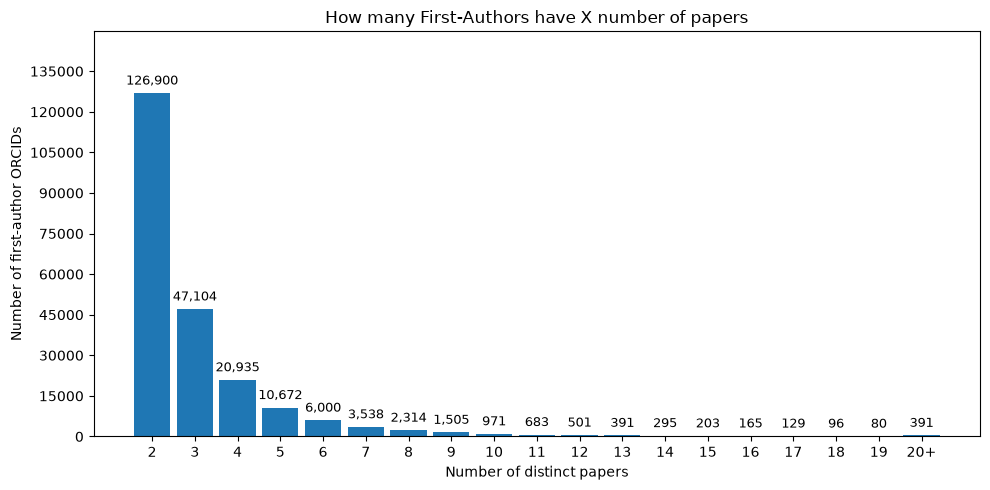

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

author_histogram = con.execute("""
    WITH first_authors AS (
        SELECT bibcode, list_distinct(list_filter([
            CASE WHEN len(orcid_pub) = len(author)
                 THEN trim(orcid_pub[1]) END,
            CASE WHEN len(orcid_user) = len(author)
                 THEN trim(orcid_user[1]) END,
            CASE WHEN len(orcid_other) = len(author)
                 THEN trim(orcid_other[1]) END
        ], lambda x: regexp_full_match(
            x, '[0-9]{4}-[0-9]{4}-[0-9]{4}-[0-9]{3}[0-9X]'
        ))) AS orcids
        FROM read_parquet(
            ?, hive_partitioning=true, union_by_name=true
        )
        WHERE year IN (SELECT unnest(?))
            AND list_contains(property, 'REFEREED')
            AND first_author = author[1]
            AND length(list_filter(
              title, lambda t: length(trim(t)) > 0
          )) > 0
          AND length(trim(abstract)) > 0
    ),
    papers_per_author AS (
        SELECT
            orcids[1] AS orcid,
            COUNT(DISTINCT bibcode) AS papers
        FROM first_authors
        WHERE len(orcids) = 1
          AND bibcode IS NOT NULL
          AND trim(bibcode) <> ''
        GROUP BY orcids[1]
    )
    SELECT papers, COUNT(*) AS authors
    FROM papers_per_author
    GROUP BY papers
    ORDER BY papers
""", [str(DATA_DIR), YEARS]).df()


from matplotlib.ticker import MaxNLocator

# Plot settings
BIN_WIDTH = 1
MIN_PAPERS = 2
MAX_PAPERS = 20  
LOG_Y = False
FIGSIZE = (10, 5)

max_papers = (
    int(author_histogram["papers"].max())
    if MAX_PAPERS is None else MAX_PAPERS
)

# Regular bins followed by an overflow bin
starts = np.append(
    np.arange(MIN_PAPERS, max_papers, BIN_WIDTH),
    max_papers,
)
edges = np.append(starts, np.inf)

counts, _ = np.histogram(
    author_histogram["papers"],
    bins=edges,
    weights=author_histogram["authors"],
)

labels = []
for start, stop in zip(starts[:-1], starts[1:]):
    end = stop - 1
    labels.append(
        str(int(start)) if start == end
        else f"{int(start)}–{int(end)}"
    )
labels.append(f"{max_papers}+")

# Discrete bar positions and integer count labels
positions = np.arange(len(counts))
fig, ax = plt.subplots(figsize=FIGSIZE)

bars = ax.bar(positions, counts, width=0.85)

ax.set_xticks(positions, labels)
ax.bar_label(
    bars,
    labels=[f"{int(count):,}" for count in counts],
    padding=4,
    fontsize=9,
)

ax.set_xlabel("Number of distinct papers")
ax.set_ylabel("Number of first-author ORCIDs")
ax.set_title("How many First-Authors have X number of papers")

if LOG_Y:
    ax.set_yscale("log")
else:
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax.margins(y=0.18)
plt.tight_layout()
plt.show()

In [13]:
paper_counts = author_histogram["papers"].to_numpy()
author_counts = author_histogram["authors"].to_numpy()

total_authors = int(author_counts.sum())
total_papers = int((paper_counts * author_counts).sum())

# Weighted median papers per author
cumulative = np.cumsum(author_counts)

def papers_at_rank(rank):
    return paper_counts[np.searchsorted(cumulative, rank, side="left")]

median_papers = (
    (
        papers_at_rank((total_authors + 1) // 2)
        + papers_at_rank(total_authors // 2 + 1)
    ) / 2
    if total_authors else np.nan
)

stats = {
    "Unique first-author ORCIDs": total_authors,
    "Distinct papers summed across authors": total_papers,
    "Authors with exactly 1 paper": int(author_counts[paper_counts == 1].sum()),
    "Authors with at least 2 papers": int(author_counts[paper_counts >= 2].sum()),
    "Authors with at least 5 papers": int(author_counts[paper_counts >= 5].sum()),
    "Authors with at least 10 papers": int(author_counts[paper_counts >= 10].sum()),
    "Mean papers per author": total_papers / total_authors if total_authors else np.nan,
    "Median papers per author": median_papers,
    "Maximum papers per author": int(paper_counts.max()) if total_authors else 0,
}

for label, value in stats.items():
    formatted = f"{value:,.2f}" if isinstance(value, (float, np.floating)) else f"{value:,}"
    print(f"{label}: {formatted}")

Unique first-author ORCIDs: 718,925
Distinct papers summed across authors: 1,175,775
Authors with exactly 1 paper: 496,052
Authors with at least 2 papers: 222,873
Authors with at least 5 papers: 27,934
Authors with at least 10 papers: 3,905
Mean papers per author: 1.64
Median papers per author: 1.00
Maximum papers per author: 143


,title_words,abstract_words
count,1175775.00,1175775.00
mean,13.26,193.86
std,4.53,75.26
min,1.00,1.00
25%,10.00,146.00
median,13.00,193.00
75%,16.00,241.00
95%,21.00,315.00
max,208.00,2921.00


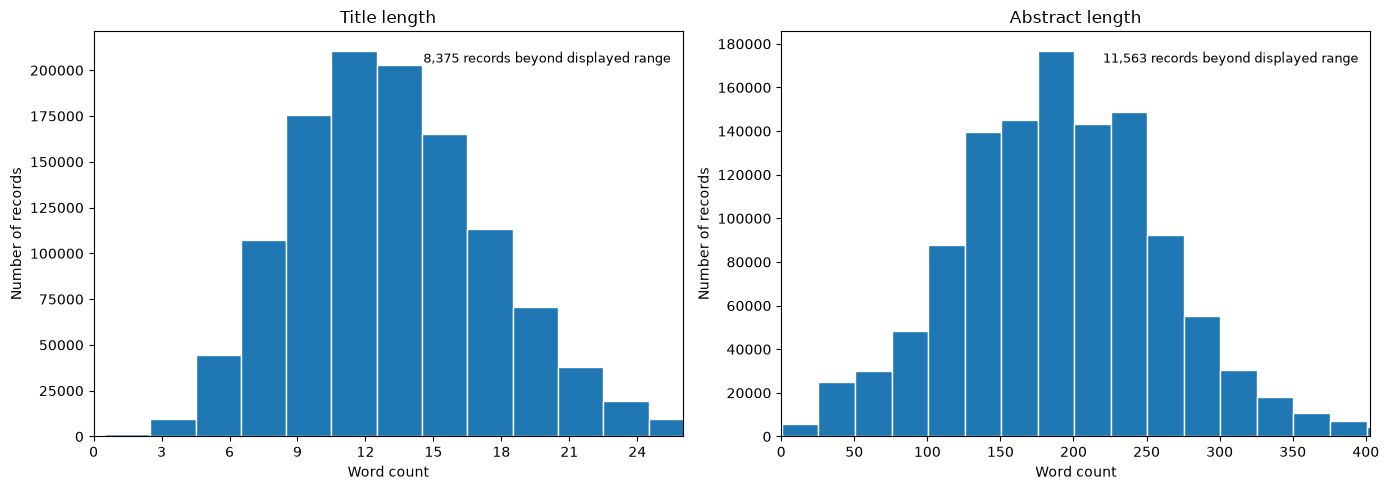

In [14]:
text_lengths = con.execute(r"""
    WITH texts AS (
        SELECT
            list_filter(title, lambda t: length(trim(t)) > 0)[1]
                AS title_text,
            abstract,
            list_distinct(list_filter([
                CASE WHEN len(orcid_pub) = len(author)
                     THEN trim(orcid_pub[1]) END,
                CASE WHEN len(orcid_user) = len(author)
                     THEN trim(orcid_user[1]) END,
                CASE WHEN len(orcid_other) = len(author)
                     THEN trim(orcid_other[1]) END
            ], lambda x: regexp_full_match(
                x, '[0-9]{4}-[0-9]{4}-[0-9]{4}-[0-9]{3}[0-9X]'
            ))) AS orcids
        FROM read_parquet(
            ?, hive_partitioning=true, union_by_name=true
        )
       WHERE year IN (SELECT unnest(?))
        AND list_contains(property, 'REFEREED')
        AND first_author = author[1]
        AND length(list_filter(
              title, lambda t: length(trim(t)) > 0
          )) > 0
          AND length(trim(abstract)) > 0
    )
    SELECT
        len(regexp_split_to_array(trim(title_text), '\s+'))
            AS title_words,
        len(regexp_split_to_array(trim(abstract), '\s+'))
            AS abstract_words
    FROM texts
    WHERE len(orcids) = 1
""", [str(DATA_DIR), YEARS]).df()

# Summary statistics across all qualifying records
display(
    text_lengths.describe(percentiles=[0.25, 0.5, 0.75, 0.95])
    .rename(index={"50%": "median"})
    .round(2)
)

# Plot settings
TITLE_BIN_WIDTH = 2
ABSTRACT_BIN_WIDTH = 25
LOG_Y = False
FIGSIZE = (14, 5)

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)

for ax, column, label, width in [
    (axes[0], "title_words", "Title", TITLE_BIN_WIDTH),
    (axes[1], "abstract_words", "Abstract", ABSTRACT_BIN_WIDTH),
]:
    values = text_lengths[column]
    bins = np.arange(0.5, values.max() + width + 0.5, width)

    ax.hist(values, bins=bins, edgecolor="white")
    ax.set_title(f"{label} length")
    ax.set_xlabel("Word count")
    ax.set_ylabel("Number of records")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    if LOG_Y:
        ax.set_yscale("log")
    else:
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
DISPLAY_PERCENTILE = 0.99  # Set to 1.0 to show the full range

for ax, column in zip(axes, ["title_words", "abstract_words"]):
    upper = int(np.ceil(text_lengths[column].quantile(DISPLAY_PERCENTILE)))
    ax.set_xlim(0, upper)

    outside = int((text_lengths[column] > upper).sum())
    ax.text(
        0.98, 0.95,
        f"{outside:,} records beyond displayed range",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
    )
    
plt.tight_layout()
plt.show()